### <font color='00ff00'> 과제1: 음원 흥행 요인 및 장르별 특성 탐색

In [ ]:
import os
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 웹(Kaggle)에서 데이터셋 다운로드 및 로컬 런타임 경로 반환
dataset_path = kagglehub.dataset_download("maharshipandya/-spotify-tracks-dataset")

# 2. 폴더 내 CSV 파일 경로 확인 및 DataFrame 로드
csv_path = os.path.join(dataset_path, "dataset.csv")
df = pd.read_csv(csv_path)

# 3. 불러온 데이터 확인
print("파일 경로:", csv_path)
print("행, 열 크기:", df.shape)
df

Using Colab cache for faster access to the '-spotify-tracks-dataset' dataset.
파일 경로: /kaggle/input/-spotify-tracks-dataset/dataset.csv
행, 열 크기: (114000, 21)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.7150,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.2670,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.1200,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.1430,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.1670,119.949,4,acoustic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
113995,113995,2C3TZjDRiAzdyViavDJ217,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Sleep My Little Boy,21,384999,False,0.172,0.2350,...,-16.393,1,0.0422,0.6400,0.928000,0.0863,0.0339,125.995,5,world-music
113996,113996,1hIz5L4IB9hN3WRYPOCGPw,Rainy Lullaby,#mindfulness - Soft Rain for Mindful Meditatio...,Water Into Light,22,385000,False,0.174,0.1170,...,-18.318,0,0.0401,0.9940,0.976000,0.1050,0.0350,85.239,4,world-music
113997,113997,6x8ZfSoqDjuNa5SVP5QjvX,Cesária Evora,Best Of,Miss Perfumado,22,271466,False,0.629,0.3290,...,-10.895,0,0.0420,0.8670,0.000000,0.0839,0.7430,132.378,4,world-music
113998,113998,2e6sXL2bYv4bSz6VTdnfLs,Michael W. Smith,Change Your World,Friends,41,283893,False,0.587,0.5060,...,-10.889,1,0.0297,0.3810,0.000000,0.2700,0.4130,135.960,4,world-music


<font color='ffff00'> 1. 수치형 컬럼의 결측치 처리 및 인기도의 기본 통계량을 산출하시오.

In [ ]:
num_cols = df.select_dtypes(include=[np.number]).columns
print("처리 전 수치형 결측치 합계:", df[num_cols].isnull().sum().sum())

df[num_cols] = df[num_cols].fillna(df[num_cols].median())
print("처리 후 수치형 결측치 합계:", df[num_cols].isnull().sum().sum())

# 인기도(popularity) 기본 통계량
pop_desc = df["popularity"].describe()
print("\n[인기도 기본 통계량]")
print(pop_desc)
print(f"중앙값(50%): {df['popularity'].median():.2f}")

처리 전 수치형 결측치 합계: 0
처리 후 수치형 결측치 합계: 0

[인기도 기본 통계량]
count    114000.000000
mean         33.238535
std          22.305078
min           0.000000
25%          17.000000
50%          35.000000
75%          50.000000
max         100.000000
Name: popularity, dtype: float64
중앙값(50%): 35.00


<font color='ffff00'> 2. 인기도가 80 이상인 상위 음원을 추출한 뒤, 장르별 top 5 곡을 도출하시오.

In [ ]:
top_popular = df[df["popularity"] >= 80].copy()

# 장르별 popularity 내림차순 상위 5곡 추출
genre_top5 = (
    top_popular.sort_values(["track_genre", "popularity"], ascending=[True, False])
    .groupby("track_genre", as_index=False)
    .head(5)
)

print(f"인기도 80 이상 총 트랙 수: {len(top_popular)}개 (장르 수: {top_popular['track_genre'].nunique()}개)")
display_cols = ["track_genre", "track_name", "artists", "album_name", "popularity"]
print(genre_top5[display_cols].head(15).to_string(index=False))

인기도 80 이상 총 트랙 수: 1201개 (장르 수: 65개)
track_genre        track_name                  artists                                      album_name  popularity
   acoustic           Hold On         Chord Overstreet                                         Hold On          82
   acoustic         I'm Yours               Jason Mraz             We Sing. We Dance. We Steal Things.          80
   alt-rock   Sweater Weather        The Neighbourhood                                     I Love You.          93
   alt-rock      Daddy Issues        The Neighbourhood                                      Wiped Out!          87
   alt-rock          Softcore        The Neighbourhood Hard To Imagine The Neighbourhood Ever Changing          86
   alt-rock    Mr. Brightside              The Killers                                        Hot Fuss          86
   alt-rock             Creep                Radiohead                                     Pablo Honey          85
alternative   Sweater Weather        The Nei

<font color='ffff00'> 3. 장르별 댄스성과 에너지의 평균을 계산하고 비교하시오.

In [ ]:
genre_audio = df.groupby("track_genre")[["danceability", "energy"]].mean()
genre_audio["diff_dance_minus_energy"] = (
    genre_audio["danceability"] - genre_audio["energy"]
)

print("[전체 장르 평균]")
print(genre_audio[["danceability", "energy"]].mean())

print("\n[댄스성(danceability) 상위 5개 장르]")
print(genre_audio.sort_values("danceability", ascending=False).head(5).round(4))

print("\n[에너지(energy) 상위 5개 장르]")
print(genre_audio.sort_values("energy", ascending=False).head(5).round(4))

[전체 장르 평균]
danceability    0.566800
energy          0.641383
dtype: float64

[댄스성(danceability) 상위 5개 장르]
               danceability  energy  diff_dance_minus_energy
track_genre                                                 
kids                 0.7789  0.6131                   0.1658
chicago-house        0.7662  0.7332                   0.0330
reggaeton            0.7585  0.7387                   0.0198
latino               0.7571  0.7318                   0.0253
reggae               0.7453  0.7258                   0.0195

[에너지(energy) 상위 5개 장르]
             danceability  energy  diff_dance_minus_energy
track_genre                                               
death-metal        0.3684  0.9315                  -0.5631
grindcore          0.2719  0.9242                  -0.6523
metalcore          0.4238  0.9145                  -0.4907
happy              0.5528  0.9110                  -0.3581
hardstyle          0.5392  0.9012                  -0.3620


<font color='ffff00'> 4. 곡의 밝기와 인기도 간 상관관계를 산점도로 시각화 하시오.

피어슨 상관계수(r): -0.0405
스피어만 상관계수(rho): -0.0419


/tmp/ipykernel_1710/2534530458.py:20: UserWarning: Glyph 44257 (\N{HANGUL SYLLABLE GOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1710/2534530458.py:20: UserWarning: Glyph 51032 (\N{HANGUL SYLLABLE YI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1710/2534530458.py:20: UserWarning: Glyph 48157 (\N{HANGUL SYLLABLE BALG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1710/2534530458.py:20: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1710/2534530458.py:20: UserWarning: Glyph 51064 (\N{HANGUL SYLLABLE IN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1710/2534530458.py:20: UserWarning: Glyph 46020 (\N{HANGUL SYLLABLE DO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51064 (\N{HANGUL SYLLABLE IN}) missing from font

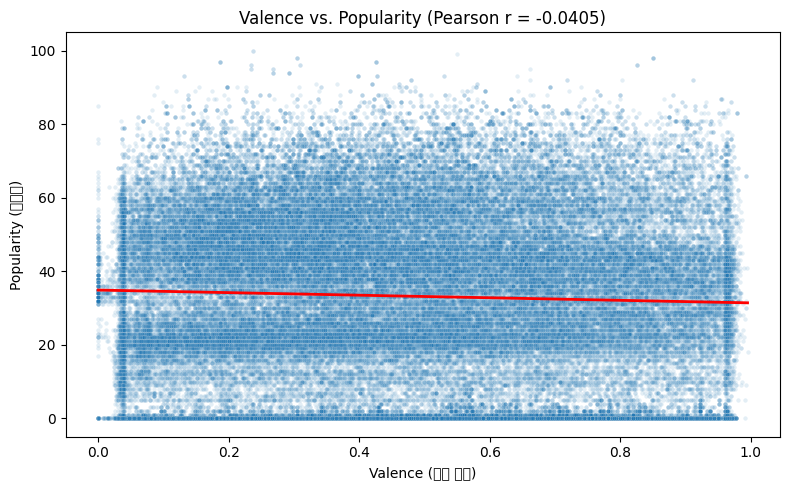

In [ ]:
pearson_r = df["valence"].corr(df["popularity"], method="pearson")
spearman_rho = df["valence"].corr(df["popularity"], method="spearman")
print(f"피어슨 상관계수(r): {pearson_r:.4f}")
print(f"스피어만 상관계수(rho): {spearman_rho:.4f}")

# 산점도 및 추세선 시각화
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="valence", y="popularity", alpha=0.12, s=10)
sns.regplot(
    data=df,
    x="valence",
    y="popularity",
    scatter=False,
    color="red",
    line_kws={"linewidth": 2},
)
plt.title(f"Valence vs. Popularity (Pearson r = {pearson_r:.4f})")
plt.xlabel("Valence (곡의 밝기)")
plt.ylabel("Popularity (인기도)")
plt.tight_layout()
plt.show()

### <font color='00ff00'> 과제2: 브라질 이커머스 다중 테이블 병합 분석

In [ ]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

# 예시: 주문 데이터(olist_orders_dataset.csv) 불러오기
orders_df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "olistbr/brazilian-ecommerce",
    "olist_orders_dataset.csv",
)

print("주문 데이터 크기:", orders_df.shape)
orders_df

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
주문 데이터 크기: (99441, 8)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00
...,...,...,...,...,...,...,...,...
99436,9c5dedf39a927c1b2549525ed64a053c,39bd1228ee8140590ac3aca26f2dfe00,delivered,2017-03-09 09:54:05,2017-03-09 09:54:05,2017-03-10 11:18:03,2017-03-17 15:08:01,2017-03-28 00:00:00
99437,63943bddc261676b46f01ca7ac2f7bd8,1fca14ff2861355f6e5f14306ff977a7,delivered,2018-02-06 12:58:58,2018-02-06 13:10:37,2018-02-07 23:22:42,2018-02-28 17:37:56,2018-03-02 00:00:00
99438,83c1379a015df1e13d02aae0204711ab,1aa71eb042121263aafbe80c1b562c9c,delivered,2017-08-27 14:46:43,2017-08-27 15:04:16,2017-08-28 20:52:26,2017-09-21 11:24:17,2017-09-27 00:00:00
99439,11c177c8e97725db2631073c19f07b62,b331b74b18dc79bcdf6532d51e1637c1,delivered,2018-01-08 21:28:27,2018-01-08 21:36:21,2018-01-12 15:35:03,2018-01-25 23:32:54,2018-02-15 00:00:00


<font color='ffff00'> 1. 주문, 결제, 고객 테이블을 order_id/customer_id 기준으로 결합하시오.

In [ ]:
path = kagglehub.dataset_download("olistbr/brazilian-ecommerce")

orders = pd.read_csv(f"{path}/olist_orders_dataset.csv")
payments = pd.read_csv(f"{path}/olist_order_payments_dataset.csv")
customers = pd.read_csv(f"{path}/olist_customers_dataset.csv")

# 2) customer_id 기준 주문 + 고객 결합, order_id 기준 결제 결합
df_merged = orders.merge(customers, on="customer_id", how="left").merge(
    payments, on="order_id", how="left"
)

print("결합 데이터 크기:", df_merged.shape)
df_merged.head()

Using Colab cache for faster access to the 'brazilian-ecommerce' dataset.
결합 데이터 크기: (103887, 16)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,payment_sequential,payment_type,payment_installments,payment_value
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,1.0,credit_card,1.0,18.12
1,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,3.0,voucher,1.0,2.00
2,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,2.0,voucher,1.0,18.59
3,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,1.0,boleto,1.0,141.46
4,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,1.0,credit_card,3.0,179.12


<font color='ffff00'> 2. 주문 일시를 datatime으로 변환한 뒤, 월별 총 매출액의 흐름을 집계하시오.

In [ ]:
df_merged["order_purchase_timestamp"] = pd.to_datetime(
    df_merged["order_purchase_timestamp"], errors="coerce"
)

# 연-월(Period) 기준 월별 총 결제액(매출액) 집계
monthly_sales = (
    df_merged.dropna(subset=["order_purchase_timestamp"])
    .assign(order_month=lambda d: d["order_purchase_timestamp"].dt.to_period("M"))
    .groupby("order_month", as_index=False)["payment_value"]
    .sum()
    .rename(columns={"payment_value": "total_sales"})
    .sort_values("order_month")
)

print(monthly_sales.to_string(index=False))

order_month  total_sales
    2016-09       252.24
    2016-10     59090.48
    2016-12        19.62
    2017-01    138488.04
    2017-02    291908.01
    2017-03    449863.60
    2017-04    417788.03
    2017-05    592918.82
    2017-06    511276.38
    2017-07    592382.92
    2017-08    674396.32
    2017-09    727762.45
    2017-10    779677.88
    2017-11   1194882.80
    2017-12    878401.48
    2018-01   1115004.18
    2018-02    992463.34
    2018-03   1159652.12
    2018-04   1160785.48
    2018-05   1153982.15
    2018-06   1023880.50
    2018-07   1066540.75
    2018-08   1022425.32
    2018-09      4439.54
    2018-10       589.67


<font color='ffff00'> 3. 주별 주문 건수 및 총 결재액과, 상위 3개 지역을 도출하시오.

In [ ]:
state_summary = (
    df_merged.groupby("customer_state", as_index=False)
    .agg(
        order_count=("order_id", "nunique"),
        total_payment=("payment_value", "sum"),
    )
    .sort_values("total_payment", ascending=False)
)

print("[전체 주별 집계 상위 10개]")
print(state_summary.head(10).to_string(index=False))

# 총 결제액 기준 상위 3개 주
top3_by_sales = state_summary.nlargest(3, "total_payment")
print("\n[총 결제액 기준 상위 3개 지역]")
print(top3_by_sales.to_string(index=False))

# 주문 건수 기준 상위 3개 지역
top3_by_orders = state_summary.nlargest(3, "order_count")
print("\n[주문 건수 기준 상위 3개 지역]")
print(top3_by_orders.to_string(index=False))

[전체 주별 집계 상위 10개]
customer_state  order_count  total_payment
            SP        41746     5998226.96
            RJ        12852     2144379.69
            MG        11635     1872257.26
            RS         5466      890898.54
            PR         5045      811156.38
            SC         3637      623086.43
            BA         3380      616645.82
            DF         2140      355141.08
            GO         2020      350092.31
            ES         2033      325967.55

[총 결제액 기준 상위 3개 지역]
customer_state  order_count  total_payment
            SP        41746     5998226.96
            RJ        12852     2144379.69
            MG        11635     1872257.26

[주문 건수 기준 상위 3개 지역]
customer_state  order_count  total_payment
            SP        41746     5998226.96
            RJ        12852     2144379.69
            MG        11635     1872257.26


<font color='ffff00'> 4. 배송 소요 기간 컬럼 생성 및 배송 지연 여부에 따른 평점을 비교하시오.

In [32]:
reviews = pd.read_csv(f"{path}/olist_order_reviews_dataset.csv")

# 리뷰 테이블 결합 (주문 단위 대표 평점 또는 전체 레코드 기준)
df_delivery = orders.merge(
    reviews[["order_id", "review_score"]], on="order_id", how="left"
)

date_cols = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for col in date_cols:
  df_delivery[col] = pd.to_datetime(df_delivery[col], errors="coerce")

# 배송 완료된 주문 대상 배송 소요기간(일) 계산
delivered = df_delivery.dropna(
    subset=["order_delivered_customer_date", "order_purchase_timestamp"]
).copy()
delivered["delivery_days"] = (
    delivered["order_delivered_customer_date"]
    - delivered["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# 배송 지연 여부: 실제 배송 완료일이 예상 배송일보다 늦은 경우
delivered["is_delayed"] = (
    delivered["order_delivered_customer_date"]
    > delivered["order_estimated_delivery_date"]
)

# 배송 지연 여부에 따른 평점(review_score) 및 평균 배송 소요기간 비교
score_comparison = delivered.groupby("is_delayed", as_index=False).agg(
    order_records=("order_id", "count"),
    mean_review_score=("review_score", "mean"),
    median_review_score=("review_score", "median"),
    mean_delivery_days=("delivery_days", "mean"),
)

print(score_comparison.to_string(index=False))

 is_delayed  order_records  mean_review_score  median_review_score  mean_delivery_days
      False          89139           4.293578                  5.0           10.890940
       True           7866           2.566550                  2.0           31.530057
